# Cluster share of the resolved light: a Gaia-only, like-for-like check

`crowding_analysis.ipynb` measured $f_{\rm cl} = F_{\rm cluster}/F_{\rm ELK}$ with literature
cluster photometry in the numerator and the ELK flux in the denominator. A fair criticism is
that the two sides don't count the same light. The ELK flux includes every faint and
unresolved source, while the literature luminosities are built from resolved, field-subtracted
stars.

This notebook uses **neither TESS fluxes nor literature photometry**. Both numerator and
denominator come from the same Gaia DR3 sources, converted to the TESS band star by star:

$$ f_{\rm cl,Gaia} \;=\; \frac{F_{\rm in} - \mu_{\rm field}\,A_{\rm ap}}{F_{\rm in}} $$

- $F_{\rm in}$ is the TESS-band flux of all Gaia sources in the ELK aperture, with
  $T = G + p(G_{BP}-G_{RP})$ from Stassun et al. (2019), or $T = G - 0.43$ when there is no
  colour. For the LMC and SMC, where the apertures are 2–3 TESS pixels across, each source is
  weighted by the fraction of its PSF inside the aperture (Gaussian, σ = 0.75 px). Sources
  just outside the aperture therefore contribute a little, and cluster light near the edge is
  partly lost, as in the real TESS photometry.
- $\mu_{\rm field}$ is the field surface brightness in an annulus (default 2–4 r_ap for the
  Clouds, 1.5–2.5 r_ap for the MW). A uniform field keeps its surface brightness under PSF
  convolution, so the expected field in the aperture is $\mu_{\rm field}A_{\rm ap}$ with no PSF term.

Choices (agreed before running): ELK's apertures are used as-is, including the SMC ones that
are 2× the intended radius; the true SMC radius is an ablation. The headline number is the
cluster share above.

**Uncertainties.**
- **Stochastic field:** the field inside the aperture is one random draw of field stars, with
  variance $(A_{\rm ap}/A_{\rm ann})\sum_{\rm ann} f_i^2$. A few bright field stars dominate it.
- **Ablations:** annulus position and width, Gaia magnitude limit (G < 17…20 vs all), stars
  without colours (dropped, or T shifted by ±0.5 mag), PSF width (0.5–1.0 px), reassigning the
  single brightest in-aperture source to the field, and the true SMC radius.

**What this can't fix:** Gaia is incomplete inside dense cluster cores. That loses cluster
light, so $f_{\rm cl,Gaia}$ is biased *low* for compact, rich Magellanic Cloud clusters.
Because unresolved light is missing from both numerator and denominator, this is a measure of
the resolved light only.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings('ignore', category=RuntimeWarning)

HERE = os.path.abspath('.')
sys.path.insert(0, HERE)
from crowd import catalogs as C, gaia_share as GS
sys.path.insert(0, os.path.join(C.LC_DIR, '..', 'Correlation_Analysis'))
import analysis_utils as A

FIG = os.path.join(HERE, 'figs'); os.makedirs(FIG, exist_ok=True)
GAL = ['MW', 'LMC', 'SMC']
COL = {'MW': '#2a78d6', 'LMC': '#eb6834', 'SMC': '#1baf7a'}
MRK = {'MW': 'o', 'LMC': 's', 'SMC': '^'}
INK, MUTED = '#2c2c2a', '#8f8e88'
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False,
                     'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': INK,
                     'ytick.color': INK, 'lines.linewidth': 2})
def save(fig, name):
    fig.savefig(os.path.join(FIG, name), dpi=150, bbox_inches='tight')

def rho_ci(x, y, n_boot=1000):
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    r, p, (lo, hi) = A.spearman_ci(x[ok], y[ok], n_boot=n_boot, seed=0)
    return r, lo, hi, p, ok.sum()

## 1 · Measurement

Gaia queries are cached in `GenerateTable_CGW/data/crowding_cache/` (`gaiashare_ring_*`: ring ×
G-magnitude sums; `gaiashare_mcrows_*`: rows within 3 r_ap for the Clouds).

In [2]:
cl = C.cluster_list()
gs = GS.measure_all(cl)
gs.to_csv(os.path.join(HERE, 'gaia_cluster_share.csv'), index=False)
summ = gs.groupby('origin').agg(n=('f_gaia', 'size'), median_f=('f_gaia', 'median'),
                                f_16=('f_gaia', lambda s: s.quantile(.16)),
                                f_84=('f_gaia', lambda s: s.quantile(.84)),
                                frac_negative=('f_gaia', lambda s: np.mean(s < 0)),
                                median_sig_stoch=('sig_stoch', 'median'),
                                median_nocol_frac=('nocol_frac', 'median'))
display(summ.loc[GAL].round(3))

        count    25%    50%    75%
origin                            
LMC     118.0  0.447  0.688  0.816
MW      124.0 -0.140  0.077  0.254
SMC     106.0 -0.183  0.134  0.344


,n,median_f,f_16,f_84,frac_negative,median_sig_stoch,median_nocol_frac
origin,,,,,,,
MW,124,0.077,-0.231,0.352,0.387,0.226,0.006
LMC,118,0.688,0.306,0.840,0.068,0.144,0.156
SMC,106,0.134,-0.328,0.444,0.406,0.321,0.108


## 2 · Cluster share of the resolved light vs age

Error bars are the stochastic-field 1σ. Negative values mean the aperture holds *less* resolved
light than the local field average: a real downward fluctuation of the field, a field gradient,
or a cluster that Gaia barely detects.

The fourth panel repeats the SMC with the **true radius**. ELK's SMC radius is Bica's axis size,
which is a diameter (Glatt's radii for the same clusters are exactly half), so the true aperture is
$r_{\rm ELK}/2$. The field annulus is kept at 2–4 $r_{\rm ELK}$. Open markers distinguish it from the
as-used SMC panel. This is the cluster's share of a correctly sized aperture, not of the light in
the ELK light curves.

In both SMC panels, grey **x** marks clusters whose true radius is below Wainer et al.'s r > 0.01°
(36″) size cut, i.e. clusters that would not be in ELK had the radius been read correctly.

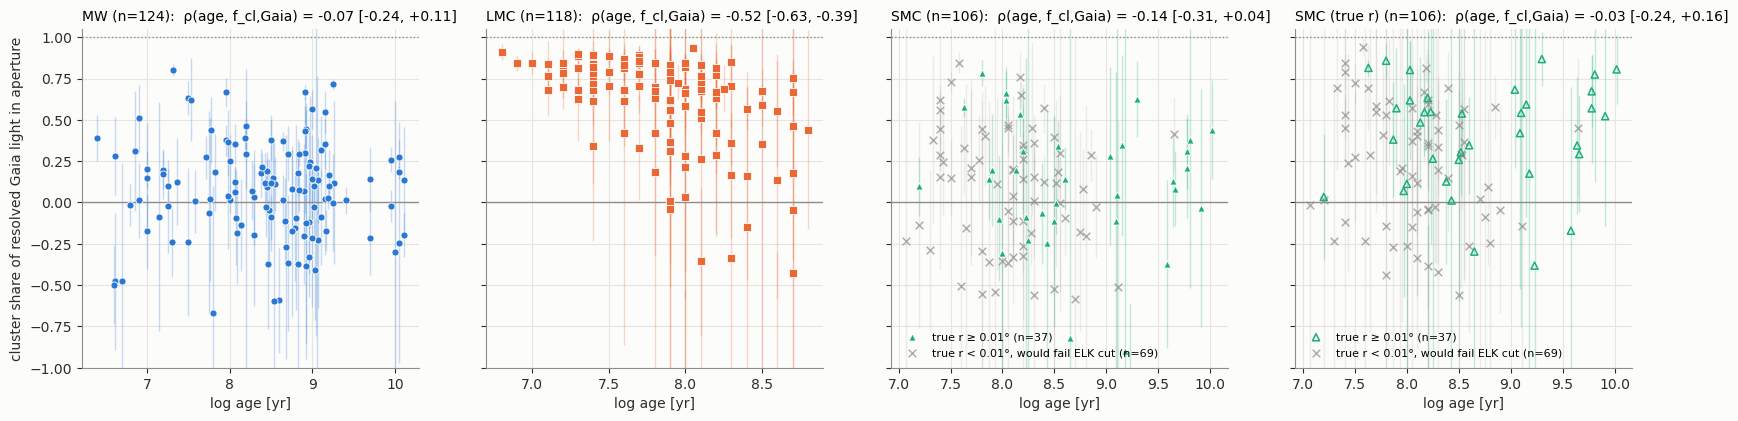

,n,median,rho_age,lo,hi,p
origin,,,,,,
MW,124,0.077,-0.069,-0.240,0.108,0.445
LMC,118,0.688,-0.523,-0.634,-0.389,0.000
SMC,106,0.134,-0.138,-0.311,0.041,0.158
SMC (true r),106,0.343,-0.031,-0.236,0.161,0.751


In [3]:
# Panels 1-3: ELK apertures as used.  Panel 4: SMC with the true radius (ELK's SMC radius is
# Bica's axis size, a diameter, so the true radius is r_ELK / 2); the annulus is unchanged.
R_CUT_ARCSEC = 0.01 * 3600                     # Wainer+23 minimum radius (0.01 deg)
PANELS = [(o, o, 'f_gaia', 'sig_stoch') for o in GAL] + [('SMC', 'SMC (true r)', 'f_true_radius', 'sig_true_radius')]
fig, axs = plt.subplots(1, 4, figsize=(20, 4.4), sharey=True)
rows = []
for ax, (o, lab, fcol, scol) in zip(axs, PANELS):
    d = gs[gs.origin == o]
    small = (d.r_ap_arcsec / 2 < R_CUT_ARCSEC).values if o == 'SMC' else np.zeros(len(d), bool)
    ax.errorbar(d.age[~small], d[fcol][~small], yerr=d[scol][~small].clip(upper=2), fmt='none', ecolor=COL[o], alpha=.25, lw=1)
    ax.errorbar(d.age[small], d[fcol][small], yerr=d[scol][small].clip(upper=2), fmt='none', ecolor=MUTED, alpha=.15, lw=1)
    open_ = fcol == 'f_true_radius'
    if o == 'SMC':
        # x = would fail Wainer+23's r > 0.01 deg (36") size cut with the true radius r_ELK / 2
        ax.scatter(d.age[~small], d[fcol][~small], s=26, marker=MRK[o], facecolor='none' if open_ else COL[o],
                   edgecolor=COL[o] if open_ else '#fcfcfb', lw=1.1 if open_ else .6, zorder=3,
                   label=f'true r ≥ 0.01° (n={(~small).sum()})')
        ax.scatter(d.age[small], d[fcol][small], s=30, marker='x', color=MUTED, alpha=.7, lw=1.1, zorder=2,
                   label=f'true r < 0.01°, would fail ELK cut (n={small.sum()})')
        ax.legend(loc='lower left', fontsize=8)
    else:
        ax.scatter(d.age, d[fcol], s=26, marker=MRK[o], color=COL[o], edgecolor='#fcfcfb', lw=.6, zorder=3)
    r, lo, hi, p, n = rho_ci(d.age, d[fcol])
    rows.append(dict(origin=lab, n=n, median=d[fcol].median(), rho_age=r, lo=lo, hi=hi, p=p))
    ax.axhline(0, color=MUTED, lw=1); ax.axhline(1, color=MUTED, lw=1, ls=':')
    ax.set(ylim=(-1, 1.05), xlabel='log age [yr]')
    ax.set_title(f'{lab} (n={n}):  ρ(age, f_cl,Gaia) = {r:+.2f} [{lo:+.2f}, {hi:+.2f}]', loc='left', fontsize=10)
axs[0].set_ylabel('cluster share of resolved Gaia light in aperture')
save(fig, 'fig_gaia_share_vs_age.png'); plt.show()
age_tab = pd.DataFrame(rows).set_index('origin'); display(age_tab.round(3))

## 3 · Agreement with the TESS-based f_cl

The first notebook's $f_{\rm cl}$ = literature cluster light / ELK flux, and the version with the
zodiacal light removed. The two methods share no inputs except the aperture, so agreement in
*ranking* (Spearman) tests whether both see the same dilution pattern. They don't have to agree
in *level*: the Gaia share ignores unresolved light on both sides, while the TESS share counts
it in the denominator only.

The fourth panel uses the SMC Gaia share with the **true radius** ($r_{\rm ELK}/2$) on the y-axis.
No TESS flux exists inside the true radius, so its x-axis is still the TESS share of the ELK aperture:
it tests whether the ranking survives, not whether the levels agree. Grey x marks clusters below
the r > 0.01° cut with the true radius, as in Section 2.

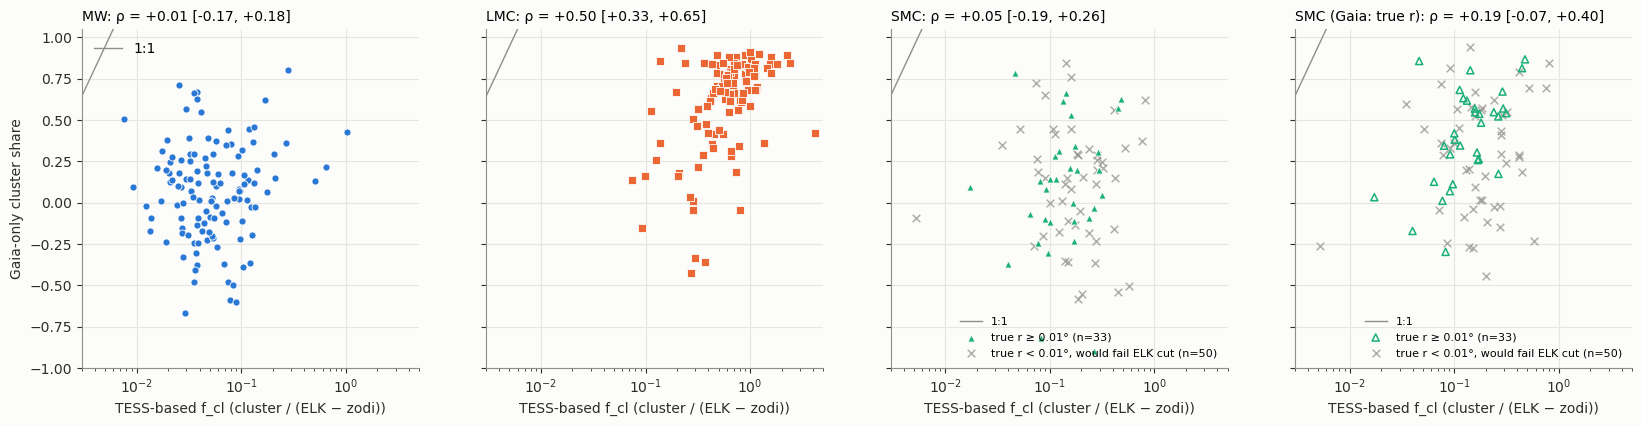

,n,rho,lo,hi,median_gaia,median_tess
origin,,,,,,
MW,124,0.012,-0.169,0.175,0.077,0.049
LMC,118,0.505,0.331,0.652,0.688,0.617
SMC,83,0.051,-0.189,0.263,0.134,0.158
SMC (Gaia: true r),83,0.193,-0.065,0.400,0.343,0.158


In [4]:
bud = pd.read_csv(os.path.join(HERE, 'crowding_budget.csv'))
j = gs.merge(bud[['name', 'f_cl', 'f_cl_astro']], on='name', how='left')
# Panel 4: SMC Gaia share with the true radius (r_ELK / 2) on the y-axis.  There is no TESS flux
# inside the true radius, so the x-axis is still the TESS-based f_cl of the ELK aperture.
PANELS3 = [(o, o, 'f_gaia') for o in GAL] + [('SMC', 'SMC (Gaia: true r)', 'f_true_radius')]
fig, axs = plt.subplots(1, 4, figsize=(20, 4.4), sharey=True)
cmp = []
for ax, (o, lab, fcol) in zip(axs, PANELS3):
    d = j[j.origin == o]
    x = np.array([1e-3, 5]); ax.plot(x, x, color=MUTED, lw=1, label='1:1')
    if o == 'SMC':
        # grey x = would fail Wainer+23's r > 0.01 deg size cut with the true radius
        small = (d.r_ap_arcsec / 2 < R_CUT_ARCSEC).values
        open_ = fcol == 'f_true_radius'
        ax.scatter(d.f_cl_astro[~small], d[fcol][~small], s=26, marker=MRK[o], facecolor='none' if open_ else COL[o],
                   edgecolor=COL[o] if open_ else '#fcfcfb', lw=1.1 if open_ else .6, zorder=3,
                   label=f'true r ≥ 0.01° (n={(~small & d.f_cl_astro.notna().values).sum()})')
        ax.scatter(d.f_cl_astro[small], d[fcol][small], s=30, marker='x', color=MUTED, alpha=.7, lw=1.1, zorder=2,
                   label=f'true r < 0.01°, would fail ELK cut (n={(small & d.f_cl_astro.notna().values).sum()})')
        ax.legend(loc='lower right', fontsize=8)
    else:
        ax.scatter(d.f_cl_astro, d[fcol], s=26, marker=MRK[o], color=COL[o], edgecolor='#fcfcfb', lw=.6)
    ax.set(xscale='log', xlim=(3e-3, 5), ylim=(-1, 1.05), xlabel='TESS-based f_cl (cluster / (ELK − zodi))')
    r, lo, hi, p, n = rho_ci(d.f_cl_astro, d[fcol])
    cmp.append(dict(origin=lab, n=n, rho=r, lo=lo, hi=hi, median_gaia=d[fcol].median(),
                    median_tess=d.f_cl_astro.median()))
    ax.set_title(f'{lab}: ρ = {r:+.2f} [{lo:+.2f}, {hi:+.2f}]', loc='left', fontsize=10)
axs[0].set_ylabel('Gaia-only cluster share'); axs[0].legend(loc='upper left')
save(fig, 'fig_gaia_vs_tess_share.png'); plt.show()
display(pd.DataFrame(cmp).set_index('origin').round(3))

### 3b · Is the agreement what we'd predict? The predicted-ratio check

The two shares have the same kind of numerator (cluster light inside the aperture) but different
denominators:

$$ f_1 = \frac{F_{\rm cl,lit}}{F_{\rm ELK}-F_{\rm zodi}}, \qquad f_2 = \frac{F_{\rm cl,Gaia}}{F_{\rm in,Gaia}} . $$

If both methods measured the **same cluster light** ($F_{\rm cl,lit} = F_{\rm cl,Gaia}$), the
Gaia share would be fully predicted by the TESS-based one:

$$ f_2^{\rm pred} = f_1\,\frac{F_{\rm ELK}-F_{\rm zodi}}{F_{\rm in,Gaia}} = \frac{F_{\rm cl,lit}}{F_{\rm in,Gaia}} . $$

The denominator ratio $(F_{\rm ELK}-F_{\rm zodi})/F_{\rm in,Gaia}$ is ~1.2–1.7 (unresolved light,
see `crowding_analysis.ipynb` §7b), so $f_1$ should come out *lower* than $f_2$ by about that
factor. The linear residual $f_2 - f_2^{\rm pred}$ works even where $f_2 < 0$.

- **Population level:** compare the observed ratio of medians, median $f_2$ / median $f_1$, with
  the median denominator ratio.
- **Per cluster:** compare $f_2$ with $f_2^{\rm pred}$. The scatter about 1:1 should be roughly the
  stochastic-field error if the numerators agree.

Here $F_{\rm in,Gaia}$ is the PSF-weighted Gaia flux used for $f_2$, and $F_{\rm cl,lit}$ is the
enclosure-corrected literature cluster flux from the first notebook.

,n,median_f1,median_f2,observed_ratio,predicted_ratio,median_f2_pred,median_resid,resid_scatter,median_sig_stoch,rho_f2_f2pred,ci
origin,,,,,,,,,,,
MW,124,0.049,0.077,1.588,1.475,0.074,-0.044,0.309,0.226,-0.072,"[-0.26, +0.10]"
LMC,118,0.617,0.688,1.115,1.287,0.800,-0.200,0.375,0.144,0.423,"[+0.24, +0.59]"
SMC,83,0.158,0.143,0.902,1.670,0.280,-0.177,0.360,0.340,-0.084,"[-0.35, +0.14]"


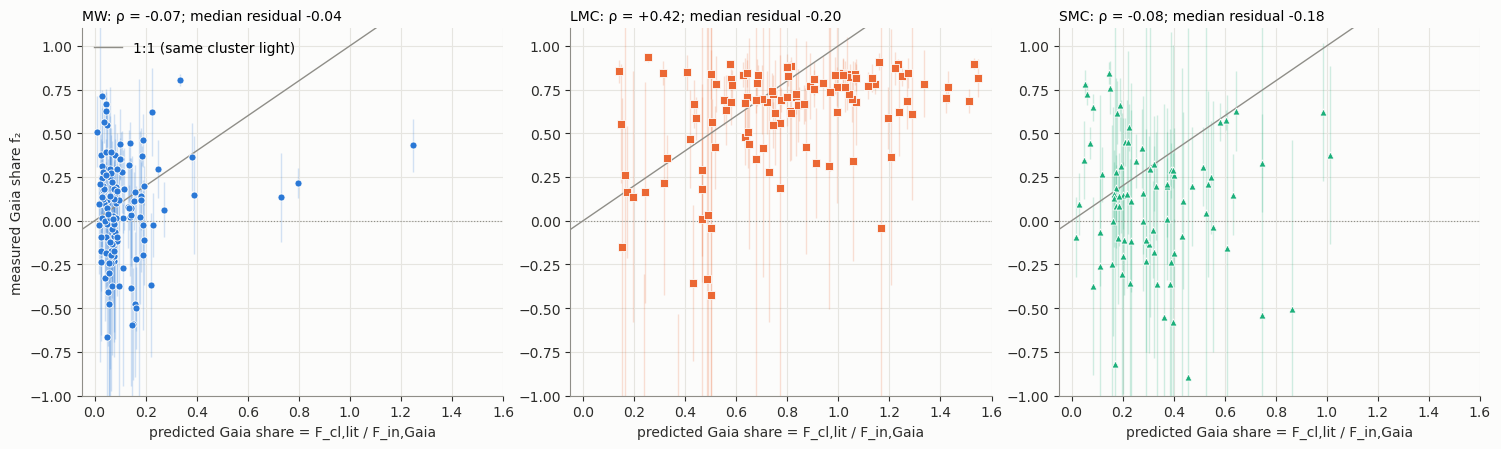

CONCLUSION —
  MW: observed median f2/f1 = 1.59 vs predicted 1.48; per-cluster residual -0.04 +/- 0.31 (stochastic error 0.23); rho(f2, f2_pred) = -0.07 [-0.26, +0.10]
  LMC: observed median f2/f1 = 1.12 vs predicted 1.29; per-cluster residual -0.20 +/- 0.37 (stochastic error 0.14); rho(f2, f2_pred) = +0.42 [+0.24, +0.59]
  SMC: observed median f2/f1 = 0.90 vs predicted 1.67; per-cluster residual -0.18 +/- 0.36 (stochastic error 0.34); rho(f2, f2_pred) = -0.08 [-0.35, +0.14]


In [5]:
pr = gs.merge(bud[['name', 'F_cl', 'F_meas', 'F_sky', 'f_cl_astro']], on='name', how='left')
pr['den_ratio'] = (pr.F_meas - pr.F_sky) / pr.F_in_gaia
pr['f2_pred'] = pr.F_cl / pr.F_in_gaia
pr['resid'] = pr.f_gaia - pr.f2_pred

rows = []
for o in GAL:
    d = pr[(pr.origin == o) & pr.f2_pred.notna()]
    r, lo, hi, p, n = rho_ci(d.f2_pred, d.f_gaia)
    rows.append(dict(origin=o, n=n,
                     median_f1=d.f_cl_astro.median(), median_f2=d.f_gaia.median(),
                     observed_ratio=d.f_gaia.median() / d.f_cl_astro.median(),
                     predicted_ratio=d.den_ratio.median(),
                     median_f2_pred=d.f2_pred.median(),
                     median_resid=d.resid.median(),
                     resid_scatter=0.5 * (d.resid.quantile(.84) - d.resid.quantile(.16)),
                     median_sig_stoch=d.sig_stoch.median(),
                     rho_f2_f2pred=r, ci=f'[{lo:+.2f}, {hi:+.2f}]'))
ratio_tab = pd.DataFrame(rows).set_index('origin')
display(ratio_tab.round(3))

fig, axs = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, o in zip(axs, GAL):
    d = pr[(pr.origin == o) & pr.f2_pred.notna()]
    ax.errorbar(d.f2_pred, d.f_gaia, yerr=d.sig_stoch.clip(upper=2), fmt='none', ecolor=COL[o], alpha=.2, lw=1)
    ax.scatter(d.f2_pred, d.f_gaia, s=26, marker=MRK[o], color=COL[o], edgecolor='#fcfcfb', lw=.6, zorder=3)
    x = np.array([-1, 3]); ax.plot(x, x, color=MUTED, lw=1, label='1:1 (same cluster light)')
    ax.axhline(0, color=MUTED, lw=.8, ls=':')
    t = ratio_tab.loc[o]
    ax.set(xlim=(-0.05, 1.6), ylim=(-1, 1.1), xlabel='predicted Gaia share = F_cl,lit / F_in,Gaia')
    ax.set_title(f'{o}: ρ = {t.rho_f2_f2pred:+.2f}; median residual {t.median_resid:+.2f}', loc='left', fontsize=10)
axs[0].set_ylabel('measured Gaia share f₂'); axs[0].legend(loc='upper left')
fig.tight_layout(); save(fig, 'fig_gaia_predicted_ratio.png'); plt.show()

print('CONCLUSION —')
for o in GAL:
    t = ratio_tab.loc[o]
    print(f'  {o}: observed median f2/f1 = {t.observed_ratio:.2f} vs predicted {t.predicted_ratio:.2f}; '
          f'per-cluster residual {t.median_resid:+.2f} +/- {t.resid_scatter:.2f} '
          f'(stochastic error {t.median_sig_stoch:.2f}); rho(f2, f2_pred) = {t.rho_f2_f2pred:+.2f} {t.ci}')

**Reading the predicted-ratio check:**
- **MW: consistent at population level only.** The observed median ratio f₂/f₁ = 1.59 matches the
  predicted 1.48, and the median residual is −0.04. Per cluster there's no correlation
  (ρ = −0.07): the scatter (0.31) is mostly the stochastic field (0.23), so individual MW
  clusters can't be checked.
- **LMC: consistent in ranking, with a ceiling.** The observed ratio is 1.12 vs 1.29 predicted,
  and the two track each other cluster by cluster (ρ = +0.42). The residual is negative (−0.20)
  because many predicted values exceed 1: the literature cluster light is larger than *all* the
  Gaia light in the aperture. That can't happen if Gaia were complete, so it shows that Gaia
  misses stars in dense LMC cluster cores. The measured share saturates near 0.8–0.9. This is
  the known bias of the Gaia method (low for compact rich clusters), not a disagreement about
  the field. The scatter (0.37) exceeds the stochastic term (0.14), so membership and bright
  supergiants add real per-cluster differences.
- **SMC: fails at population level.** The observed ratio is 0.90 vs 1.67 predicted, the median
  residual is −0.18, and ρ ≈ 0. The population medians agreed only by coincidence. Gaia recovers
  about half the cluster light the literature implies, consistent with crowded SMC cores plus
  ELK's 4×-area SMC apertures diluting the Gaia signal into noise (σ ≈ 0.34).

So the close agreement in the medians is expected from the measured ELK/Gaia flux ratio for
the MW and LMC. For the SMC it's a coincidence of two biases that roughly cancel.

## 4 · Ablations

Each variant changes one choice and keeps the others at their defaults. For each galaxy the
table gives the median cluster share, the median per-cluster shift from the default, and the
age correlation. That last column is the question that matters downstream: **does the
LMC/SMC age trend survive every choice?**

In [6]:
VARIANTS = {'default': 'f_gaia'}
for o in GAL:
    for a in GS.ANNULI[o][1:]:
        VARIANTS[f'annulus {a[0]:g}–{a[1]:g} r_ap'] = f'f_ann_{a[0]:g}_{a[1]:g}'
for g in GS.G_CUTS[:-1]:
    VARIANTS[f'G < {g:g}'] = f'f_G{g:g}'
VARIANTS.update({'no-colour stars dropped': 'f_nocol_drop', 'no-colour T + 0.5': 'f_nocol_p05',
                 'no-colour T − 0.5': 'f_nocol_m05', 'PSF σ = 0.5 px': 'f_psf_0.5',
                 'PSF σ = 1.0 px': 'f_psf_1', 'brightest source → field': 'f_drop1',
                 'SMC true radius (r/2)': 'f_true_radius'})
abl = []
for lab, col in VARIANTS.items():
    for o in GAL:
        d = gs[gs.origin == o]
        if col not in d or d[col].notna().sum() < 10:
            continue
        r, lo, hi, p, n = rho_ci(d.age, d[col], n_boot=500)
        abl.append(dict(variant=lab, origin=o, n=n, median=d[col].median(),
                        median_shift=(d[col] - d.f_gaia).median(), rho_age=r, lo=lo, hi=hi))
abl = pd.DataFrame(abl)
wide = abl.pivot(index='variant', columns='origin', values=['median', 'rho_age'])
wide = wide.reindex([v for v in VARIANTS if v in wide.index])
display(wide.round(2))

median             rho_age            
origin                      LMC    MW   SMC     LMC    MW   SMC
variant                                                        
default                    0.69  0.08  0.13   -0.52 -0.07 -0.14
annulus 2–3 r_ap            NaN  0.10   NaN     NaN -0.01   NaN
annulus 2.5–4 r_ap          NaN  0.03   NaN     NaN  0.06   NaN
annulus 1.25–2 r_ap         NaN  0.08   NaN     NaN  0.01   NaN
annulus 1.5–2.5 r_ap       0.70   NaN  0.16   -0.53   NaN -0.04
annulus 3–5 r_ap           0.69   NaN  0.10   -0.55   NaN -0.21
annulus 4–6 r_ap           0.67   NaN  0.07   -0.50   NaN -0.30
G < 17                     0.74  0.11  0.03   -0.55 -0.07 -0.24
G < 18                     0.73  0.10  0.06   -0.56 -0.07 -0.22
G < 19                     0.71  0.09  0.11   -0.54 -0.07 -0.19
G < 20                     0.70  0.08  0.13   -0.53 -0.07 -0.15
no-colour stars dropped    0.64  0.08  0.08   -0.53 -0.08 -0.13
no-colour T + 0.5          0.67  0.08  0.13   -0.53 -0.07 -0.13
no-colour T − 0.5          0.71  0.08  0.14   -0.51 -0.06 -0.13
PSF σ = 0.5 px             0.70   NaN  0.13   -0.51   NaN -0.12
PSF σ = 1.0 px             0.67   NaN  0.14   -0.53   NaN -0.14
brightest source → field   0.53 -0.06  0.01   -0.43 -0.04 -0.09
SMC true radius (r/2)       NaN   NaN  0.34     NaN   NaN -0.03

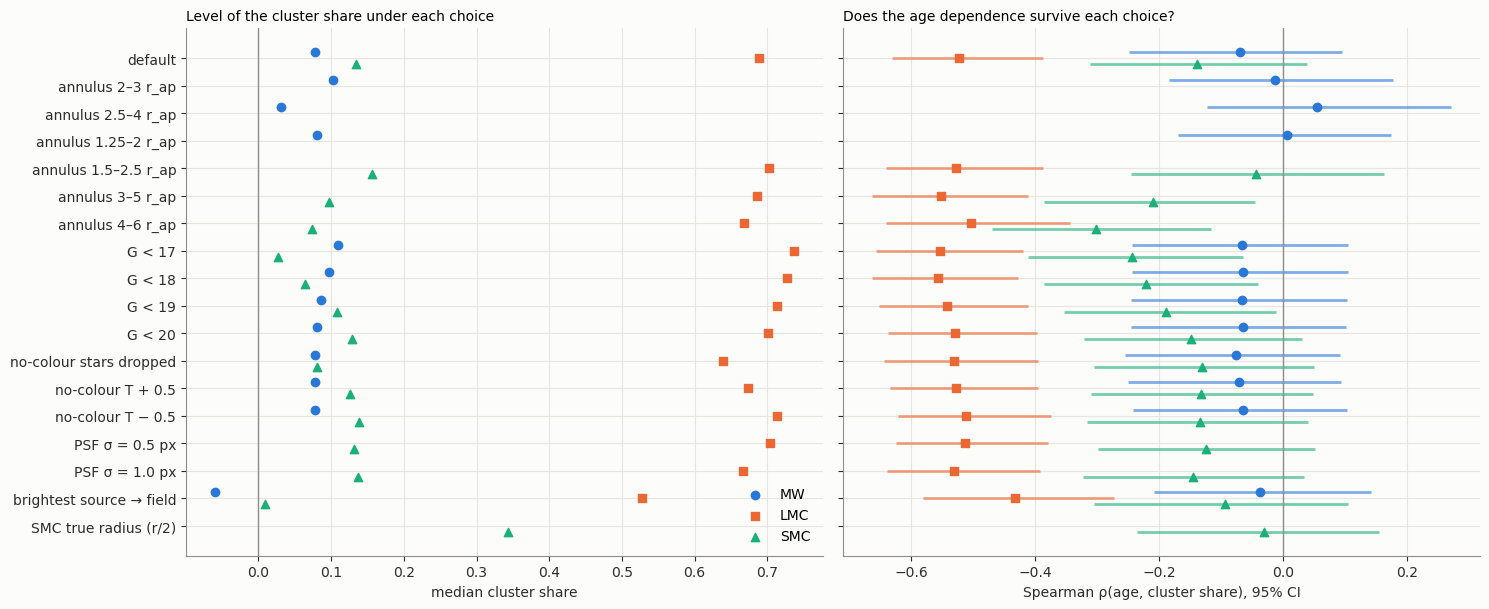

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(15, 6.2), sharey=True)
order = [v for v in VARIANTS if v in set(abl.variant)]
y = {v: i for i, v in enumerate(order[::-1])}
off = {'MW': .22, 'LMC': 0.0, 'SMC': -.22}
for o in GAL:
    d = abl[abl.origin == o]
    yy = np.array([y[v] for v in d.variant]) + off[o]
    axs[0].scatter(d['median'], yy, marker=MRK[o], color=COL[o], s=36, label=o, zorder=3)
    axs[1].hlines(yy, d.lo, d.hi, color=COL[o], lw=2, alpha=.6)
    axs[1].scatter(d.rho_age, yy, marker=MRK[o], color=COL[o], s=36, zorder=3, label=o)
for ax in axs:
    ax.set_yticks(list(y.values())); ax.set_yticklabels(list(y.keys()))
axs[0].axvline(0, color=MUTED, lw=1); axs[1].axvline(0, color=MUTED, lw=1)
axs[0].set(xlabel='median cluster share'); axs[0].set_title('Level of the cluster share under each choice', loc='left', fontsize=10)
axs[1].set(xlabel='Spearman ρ(age, cluster share), 95% CI')
axs[1].set_title('Does the age dependence survive each choice?', loc='left', fontsize=10)
axs[0].legend(loc='lower right')
fig.tight_layout(); save(fig, 'fig_gaia_share_ablations.png'); plt.show()

### 4a · Magnitude limit in detail

If faint stars mattered, the cluster share would move steadily as the Gaia limit deepens.

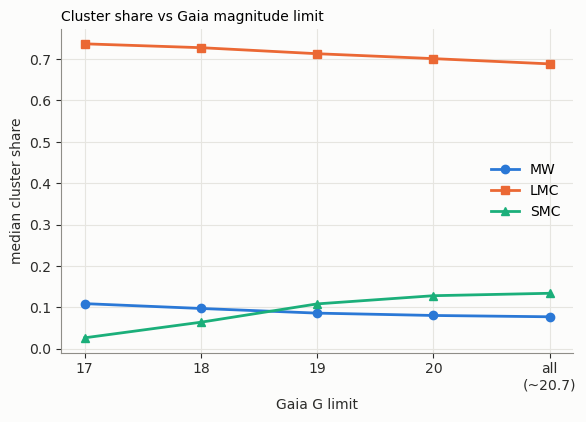

In [8]:
fig, ax = plt.subplots(figsize=(6.6, 4.2))
cuts = [17, 18, 19, 20, 21]
for o in GAL:
    d = gs[gs.origin == o]
    med = [d[f'f_G{c}'].median() for c in cuts[:-1]] + [d.f_gaia.median()]
    ax.plot(cuts, med, color=COL[o], marker=MRK[o], label=o)
ax.set_xticks(cuts); ax.set_xticklabels(['17', '18', '19', '20', 'all\n(~20.7)'])
ax.set(xlabel='Gaia G limit', ylabel='median cluster share')
ax.set_title('Cluster share vs Gaia magnitude limit', loc='left', fontsize=10)
ax.legend(); save(fig, 'fig_gaia_share_maglimit.png'); plt.show()

### 4b · Bright-end cut: does removing bright stars reduce the noise?

Section 4a removed *faint* stars. Here the cut runs the other way: sources with G < G_min are
dropped from the aperture **and** the annulus. The stochastic-field variance
$(A_{\rm ap}/A_{\rm ann})\sum_{\rm ann} f_i^2$ is a sum of squared fluxes, so the few brightest
field stars dominate it, and this cut should shrink it sharply.

**Caveat: this changes the quantity being measured.** The result is the cluster share of the
light from stars fainter than G_min. The TESS aperture still contains the bright stars, whether
they are field or cluster members (e.g. supergiants in young LMC clusters). So the cut is a
diagnostic of *where the noise and signal come from*, not a better estimator of the dilution
that applies to the light curve. It is therefore left out of the uncertainty budget below.

n  median    q16    q84  frac_negative  median_sig  median_shift  rho_age     lo     hi
origin G_min                                                                                           
MW     none   124   0.077 -0.231  0.352          0.387       0.226         0.000   -0.069 -0.248  0.095
       10.0   124   0.103 -0.038  0.252          0.258       0.078         0.036    0.005 -0.170  0.191
       12.0   124   0.093 -0.040  0.245          0.266       0.043         0.044    0.051 -0.129  0.231
       13.0   124   0.105 -0.051  0.237          0.234       0.034         0.022    0.095 -0.092  0.273
       14.0   124   0.094 -0.038  0.220          0.258       0.026         0.022    0.075 -0.116  0.246
       15.0   124   0.087 -0.035  0.201          0.226       0.021         0.000    0.109 -0.077  0.282
       16.0   124   0.076 -0.031  0.205          0.226       0.017        -0.013    0.107 -0.067  0.275
LMC    none   118   0.688  0.306  0.840          0.068       0.144         0.000   -0.523 -0.631 -0.387
       10.0   118   0.689  0.325  0.840          0.051       0.144         0.000   -0.539 -0.643 -0.403
       12.0   118   0.698  0.481  0.831          0.008       0.128         0.000   -0.511 -0.625 -0.362
       13.0   118   0.701  0.523  0.820          0.008       0.101         0.000   -0.391 -0.518 -0.235
       14.0   118   0.697  0.519  0.809          0.008       0.083         0.011   -0.286 -0.445 -0.126
       15.0   118   0.668  0.465  0.787          0.017       0.074        -0.010   -0.163 -0.328  0.025
       16.0   118   0.663  0.461  0.770          0.008       0.062        -0.028   -0.063 -0.241  0.119
SMC    none   106   0.134 -0.328  0.444          0.406       0.321         0.000   -0.138 -0.312  0.040
       10.0   106   0.154 -0.249  0.448          0.330       0.306         0.000   -0.083 -0.267  0.109
       12.0   106   0.215 -0.111  0.425          0.236       0.200         0.043   -0.005 -0.202  0.199
       13.0   106   0.230 -0.010  0.426          0.170       0.159         0.100    0.041 -0.181  0.237
       14.0   106   0.235  0.039  0.448          0.142       0.120         0.115    0.088 -0.127  0.291
       15.0   106   0.239  0.002  0.400          0.151       0.095         0.135    0.134 -0.079  0.335
       16.0   106   0.226  0.050  0.413          0.075       0.076         0.144    0.167 -0.051  0.369

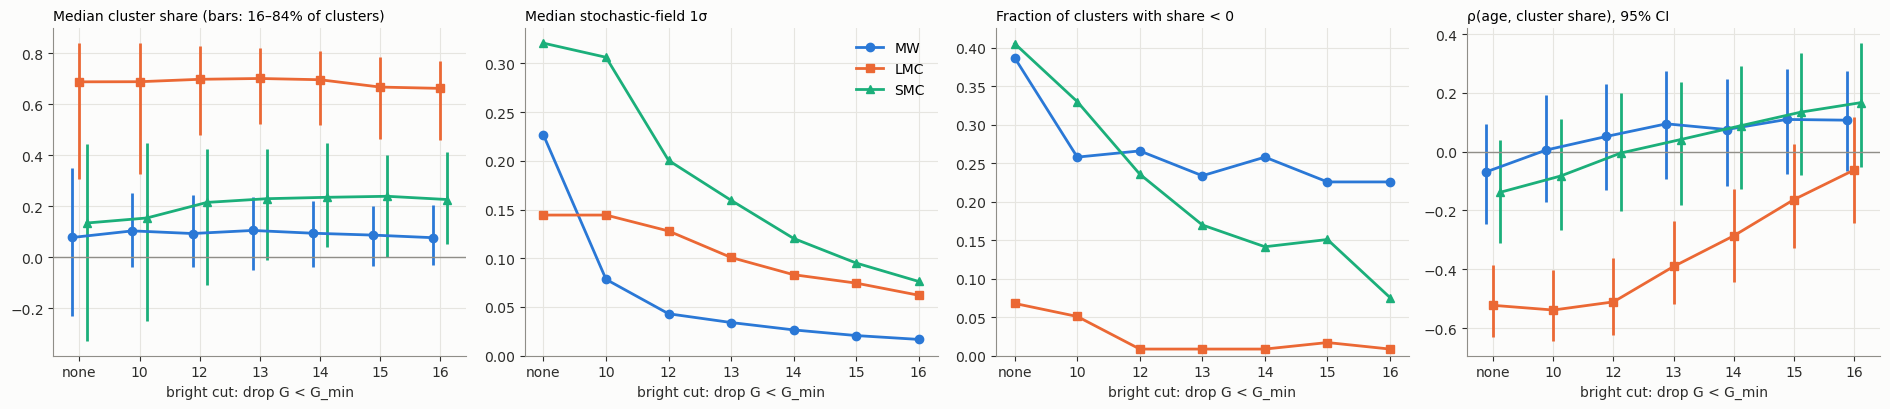

In [9]:
cuts = [None] + GS.G_BRIGHT
lab = ['none'] + [f'{g:g}' for g in GS.G_BRIGHT]
br = []
for o in GAL:
    d = gs[gs.origin == o]
    for g in cuts:
        fc, sc = ('f_gaia', 'sig_stoch') if g is None else (f'f_Gmin{g:g}', f'sig_Gmin{g:g}')
        r, lo, hi, p, n = rho_ci(d.age, d[fc], n_boot=500)
        br.append(dict(origin=o, G_min='none' if g is None else g, n=n, median=d[fc].median(),
                       q16=d[fc].quantile(.16), q84=d[fc].quantile(.84),
                       frac_negative=np.mean(d[fc] < 0), median_sig=d[sc].median(),
                       median_shift=(d[fc] - d.f_gaia).median(), rho_age=r, lo=lo, hi=hi))
br = pd.DataFrame(br)
display(br.set_index(['origin', 'G_min']).round(3))

fig, axs = plt.subplots(1, 4, figsize=(19, 4.2))
x = np.arange(len(cuts)); off = {'MW': -.12, 'LMC': 0.0, 'SMC': .12}
for o in GAL:
    d = br[br.origin == o]
    axs[0].errorbar(x + off[o], d['median'], yerr=[d['median'] - d.q16, d.q84 - d['median']],
                    color=COL[o], marker=MRK[o], capsize=0, label=o)
    axs[1].plot(x, d.median_sig, color=COL[o], marker=MRK[o], label=o)
    axs[2].plot(x, d.frac_negative, color=COL[o], marker=MRK[o], label=o)
    axs[3].errorbar(x + off[o], d.rho_age, yerr=[d.rho_age - d.lo, d.hi - d.rho_age],
                    color=COL[o], marker=MRK[o], capsize=0, label=o)
titles = ['Median cluster share (bars: 16–84% of clusters)', 'Median stochastic-field 1σ',
          'Fraction of clusters with share < 0', 'ρ(age, cluster share), 95% CI']
for ax, t in zip(axs, titles):
    ax.set_xticks(x); ax.set_xticklabels(lab); ax.set_xlabel('bright cut: drop G < G_min')
    ax.set_title(t, loc='left', fontsize=10)
axs[0].axhline(0, color=MUTED, lw=1); axs[3].axhline(0, color=MUTED, lw=1)
axs[1].set_ylim(0); axs[2].set_ylim(0); axs[1].legend(loc='upper right')
fig.tight_layout(); save(fig, 'fig_gaia_share_brightcut.png'); plt.show()

### 4c · Would a bigger background annulus help?

Two separate noise terms enter the subtracted field:

1. **The field inside the aperture is one random draw.** Its variance is
   $A_{\rm ap}\,s_2$, where $s_2 = \sum f_i^2 / A$ is the per-area second moment of the field.
   It is set by the aperture alone. No annulus can remove it, because those particular field
   stars really are in the TESS light curve.
2. **Error on the mean field** estimated from the annulus: $A_{\rm ap}^2\,s_2/A_{\rm ann}$.
   Only this term shrinks with a larger annulus.

So $\sigma_{\rm tot} = \sigma_{\rm stoch}\sqrt{1 + A_{\rm ap}/A_{\rm ann}}$. The default
`sig_stoch` reports term 1 only. The table gives the inflation factor for each annulus and the
largest possible gain ($A_{\rm ann}\to\infty$).

In [10]:
ann = []
for o in GAL:
    for a in GS.ANNULI[o]:
        ratio = a[1] ** 2 - a[0] ** 2                      # A_ann / A_ap
        ann.append(dict(origin=o, annulus=f'{a[0]:g}–{a[1]:g} r_ap', A_ann_over_A_ap=ratio,
                        sigma_inflation=np.sqrt(1 + 1 / ratio),
                        max_gain_pct=100 * (1 - 1 / np.sqrt(1 + 1 / ratio))))
display(pd.DataFrame(ann).set_index(['origin', 'annulus']).round(3))

A_ann_over_A_ap  sigma_inflation  max_gain_pct
origin annulus                                                     
MW     1.5–2.5 r_ap            4.000            1.118        10.557
       2–3 r_ap                5.000            1.095         8.713
       2.5–4 r_ap              9.750            1.050         4.765
       1.25–2 r_ap             2.438            1.188        15.792
LMC    2–4 r_ap               12.000            1.041         3.923
       1.5–2.5 r_ap            4.000            1.118        10.557
       3–5 r_ap               16.000            1.031         2.986
       4–6 r_ap               20.000            1.025         2.410
SMC    2–4 r_ap               12.000            1.041         3.923
       1.5–2.5 r_ap            4.000            1.118        10.557
       3–5 r_ap               16.000            1.031         2.986
       4–6 r_ap               20.000            1.025         2.410

**Reading 4b and 4c:**

- **Bright cut (4b).** Dropping bright stars cuts the stochastic noise by 2–10× and the
  fraction of negative shares sharply (MW 39% → ~23%, SMC 41% → 8–15%, LMC 7% → ~1%). The
  negative fraction under the default was roughly what Gaussian noise of size σ predicts
  around the median, e.g. Φ(−0.08/0.23) ≈ 36% for the MW. So the negative values are this noise,
  not a bug. The median share barely moves in the MW (0.08 → 0.08–0.10) or LMC (0.69 → 0.66–0.70).
  It rises in the SMC (0.13 → ~0.23), where bright foreground or field stars inflate the annulus.
- **The remaining MW negatives aren't noise.** With G ≥ 14 the MW σ falls to ~0.03, yet ~23% of
  MW clusters are still negative. Their apertures hold less faint-star light than the annulus.
  That points to a systematic: a field gradient or patchy extinction across the 1.5–2.5 r_ap
  annulus, or a cluster too sparse to show against the field. In the MW the annulus error
  (section 5) matters as much as the stochastic term once bright stars are removed.
- **But the LMC age trend disappears with the bright stars** (ρ −0.52 → −0.29 at G ≥ 14 and
  −0.06 at G ≥ 16). The age dependence of LMC dilution is carried by bright stars: young
  clusters own their luminous supergiants and giants, and old clusters don't. That is the
  physics we want, and it's exactly the light the TESS aperture sees. So the bright cut
  explains the noise rather than fixing it. The default (all stars) remains the right
  dilution estimate, and its noise is real field-star sampling in the light curve itself.
- **Annulus size (4c).** The gain is negligible: at most ~4% in σ for the default LMC/SMC
  annulus and ~11% for the MW. The noise is the variance of the field *inside the
  aperture* (per-area variance × aperture area), not the error on the background mean. A larger
  annulus also reaches further from the cluster, which raises the risk of field gradients. The
  annulus ablations in section 4 therefore probe gradients, not noise.

## 5 · Uncertainty budget

For each cluster, the systematic spread of each ablation family is the half-range of its
variants (including the default). These are combined in quadrature with the stochastic-field
term. The table gives medians over clusters.

In [11]:
fam = {'annulus': [c for c in gs.columns if c.startswith('f_ann_')],
       'magnitude limit': [c for c in gs.columns if c.startswith('f_G') and not c.startswith('f_Gmin')],
       'colour completeness': ['f_nocol_drop', 'f_nocol_p05', 'f_nocol_m05'],
       'PSF width': ['f_psf_0.5', 'f_psf_1']}
U = pd.DataFrame(index=gs.index)
for k, cols in fam.items():
    v = gs[cols + ['f_gaia']]
    U[k] = 0.5 * (v.max(axis=1) - v.min(axis=1))
U['stochastic field'] = gs.sig_stoch
U['total'] = np.sqrt((U.fillna(0) ** 2).sum(axis=1))
U['origin'] = gs.origin
budget = U.groupby('origin').median().loc[GAL].T
display(budget.round(3))
gs['sig_total'] = U['total']
gs.to_csv(os.path.join(HERE, 'gaia_cluster_share.csv'), index=False)

origin,MW,LMC,SMC
annulus,0.112,0.075,0.147
magnitude limit,0.011,0.026,0.088
colour completeness,0.001,0.032,0.028
PSF width,0.000,0.017,0.012
stochastic field,0.226,0.144,0.321
total,0.278,0.210,0.417


## 6 · LMC: does the Gaia-only dilution track the amplitude like the TESS-based one?

In [12]:
GT = os.path.join(C.LC_DIR, '..', 'GenerateTable_CGW', 'data')
rows_ct = A.load_rows(os.path.join(GT, 'cluster_table_Sep23_all_combos_le3sectors.pkl'), verbose=False)
ct = A.cluster_table(rows_ct)[['name', 'intrinsic_std']]
k = gs.merge(ct, on='name', how='inner')
out = []
for o in GAL:
    d = k[k.origin == o]
    r1 = rho_ci(d.intrinsic_std, d.f_gaia); r2 = rho_ci(d.intrinsic_std, d.age)
    out.append(dict(origin=o, n=r1[4], rho_amp_fGaia=r1[0], ci=f'[{r1[1]:+.2f}, {r1[2]:+.2f}]',
                    rho_amp_age=r2[0], ci_age=f'[{r2[1]:+.2f}, {r2[2]:+.2f}]'))
display(pd.DataFrame(out).set_index('origin').round(2))

,n,rho_amp_fGaia,ci,rho_amp_age,ci_age
origin,,,,,
MW,124,0.30,"[+0.13, +0.44]",-0.30,"[-0.45, -0.12]"
LMC,118,0.14,"[-0.03, +0.30]",-0.25,"[-0.42, -0.07]"
SMC,99,0.07,"[-0.14, +0.28]",-0.22,"[-0.39, -0.04]"


## 7 · Conclusions

In [13]:
print('CONCLUSION —')
for o in GAL:
    a = age_tab.loc[o]; b = budget[o]
    print(f'  {o}: median Gaia cluster share {a["median"]:.2f}; rho(age) = {a.rho_age:+.2f} '
          f'[{a.lo:+.2f}, {a.hi:+.2f}]; typical total 1-sigma {b["total"]:.2f} '
          f'(stochastic {b["stochastic field"]:.2f}, annulus {b["annulus"]:.2f}, '
          f'mag limit {b["magnitude limit"]:.2f}, colour {b["colour completeness"]:.2f})')
ra = abl[abl.origin == 'LMC']
print(f'  LMC age correlation across all {len(ra)} variants: {ra.rho_age.min():+.2f} to {ra.rho_age.max():+.2f}')
rs = abl[abl.origin == 'SMC']
print(f'  SMC age correlation across all {len(rs)} variants: {rs.rho_age.min():+.2f} to {rs.rho_age.max():+.2f}')

CONCLUSION —
  MW: median Gaia cluster share 0.08; rho(age) = -0.07 [-0.24, +0.11]; typical total 1-sigma 0.28 (stochastic 0.23, annulus 0.11, mag limit 0.01, colour 0.00)
  LMC: median Gaia cluster share 0.69; rho(age) = -0.52 [-0.63, -0.39]; typical total 1-sigma 0.21 (stochastic 0.14, annulus 0.07, mag limit 0.03, colour 0.03)
  SMC: median Gaia cluster share 0.13; rho(age) = -0.14 [-0.31, +0.04]; typical total 1-sigma 0.42 (stochastic 0.32, annulus 0.15, mag limit 0.09, colour 0.03)
  LMC age correlation across all 14 variants: -0.56 to -0.43
  SMC age correlation across all 15 variants: -0.30 to -0.03


**What the Gaia-only measurement says** (values from the cells above):

1. **LMC: the dilution result holds without TESS fluxes or literature photometry.** The median
   cluster share of resolved light is 0.69 (16–84%: 0.31–0.84), close to the TESS-based 0.62. The
   two methods rank clusters consistently (ρ = +0.51). The share falls with age,
   ρ = −0.52 [−0.63, −0.39], and stays between −0.43 and −0.56 across **all 14 ablations**.
   The Gaia magnitude limit barely matters (0.74 at G < 17 vs 0.69 for all stars), so faint
   sources aren't driving it. That addresses the "TESS sees faint light the literature
   doesn't" criticism for the LMC.
2. **MW: mostly field, as before.** The median share is 0.08 (TESS-based 0.05), but the
   per-cluster noise (σ ≈ 0.28, mostly the stochastic field) is as large as the signal, and
   39% of clusters come out negative: Gaia can't separate many MW clusters from their field at
   all. There is no age dependence (ρ ≈ −0.07). This agrees with the photometry route, but the
   noise can't rule out the mild trend the mass route suggested.
3. **SMC: too noisy to confirm the TESS-based trend.** The median share is 0.13 (TESS-based
   0.16), σ ≈ 0.42, and 41% of clusters are negative. The age correlation is −0.14 and moves
   between −0.03 and −0.30 depending on the annulus, so it is not robust. The true-radius
   ablation raises the median share from 0.13 to 0.34, which quantifies the cost of ELK's
   doubled SMC apertures.
4. **Uncertainty budget.** The stochastic field (which field stars happen to fall in the
   aperture) dominates everywhere (0.14 LMC, 0.23 MW, 0.32 SMC). The annulus choice comes next
   (0.07–0.15). The magnitude limit (≤ 0.09), colour completeness (≤ 0.03) and PSF width
   (≤ 0.02) are minor. Stars without Gaia colours carry ~16% of in-aperture flux in the LMC
   (crowded cores), and dropping them lowers the share (0.69 → 0.64) without changing the trend.
5. **Single bright stars matter.** Reassigning the brightest in-aperture source to the field
   lowers the LMC median from 0.69 to 0.53 and weakens the trend to −0.43. Part of the "cluster"
   light in young LMC apertures is one or two supergiants, which may be members or not.
6. **Amplitude link.** The LMC amplitude correlates more weakly with the Gaia share
   (ρ = +0.14 [−0.03, +0.30]) than with the TESS-based share (+0.26). This is expected, since the
   Gaia share doesn't count unresolved light in the denominator. In the MW the amplitude
   tracks the Gaia share (+0.30), but MW share doesn't depend on age, so it can't drive the MW
   amplitude–age trend.

**Bottom line:** for the LMC, two independent methods (TESS flux + literature photometry, and
Gaia only) agree on the level of dilution and on its age dependence. For the SMC and MW, the
Gaia-only method confirms heavy dilution but is too noisy per cluster to test the age
dependence.